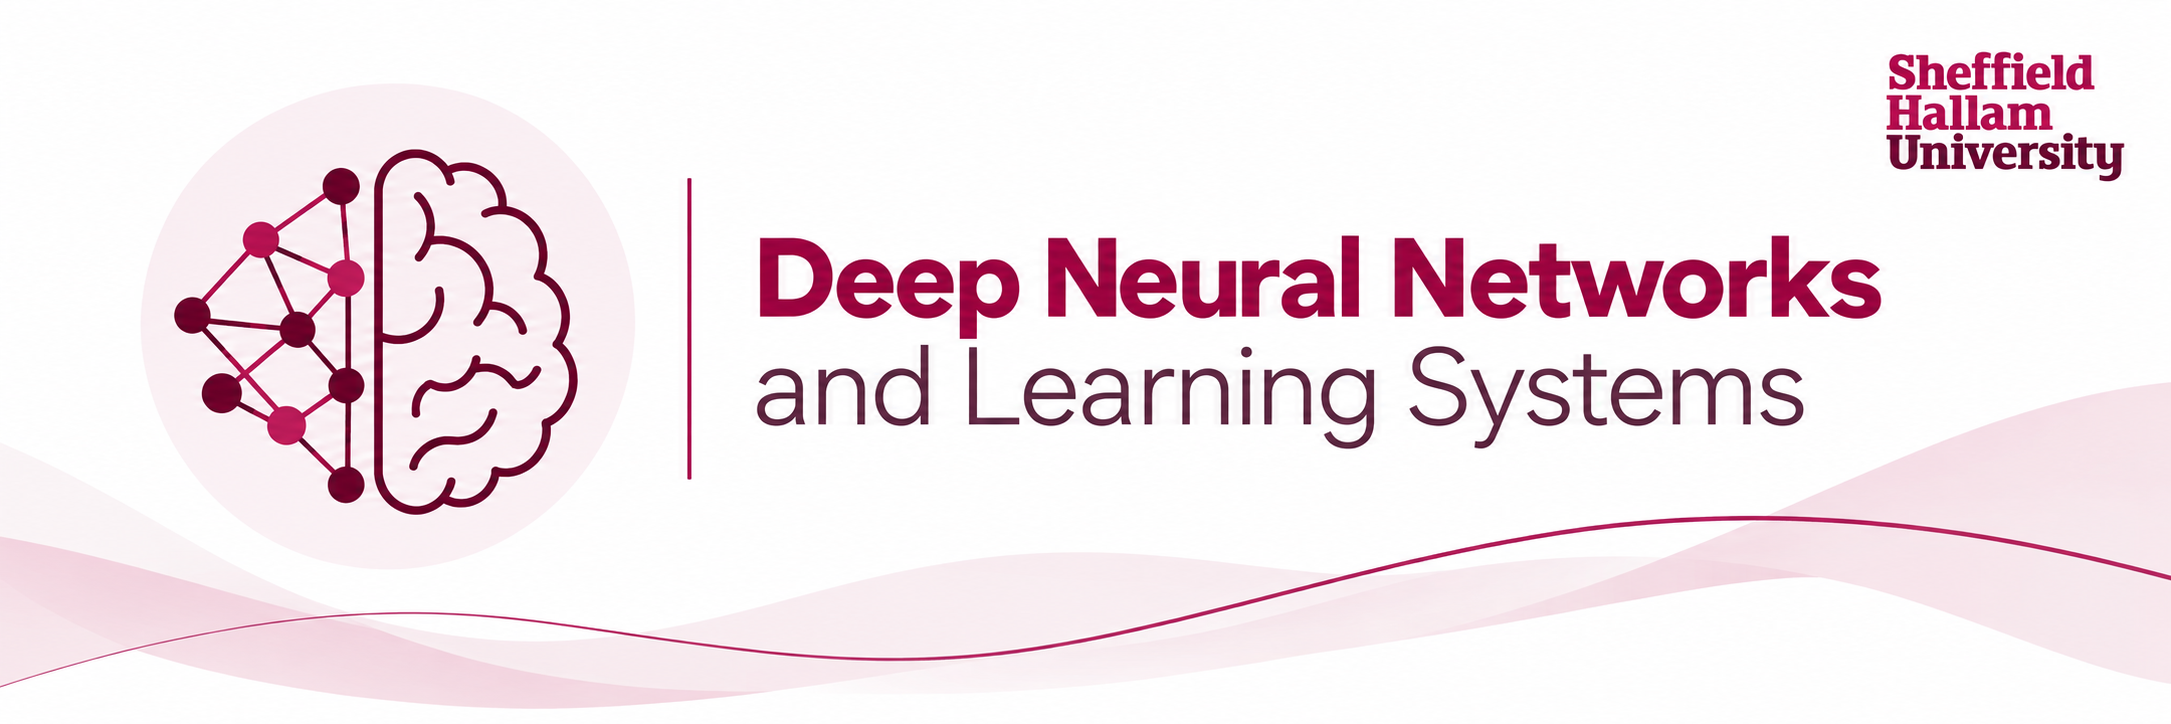

# StoryReasoning prepared data for the assessment

This notebook shows how to reach every piece of the prepared data from Colab: a story, a frame, its
tables, its grounded text, the frozen features, and the picture itself (fetched lazily from the
original Hugging Face dataset only when you ask for it).

**Where the data is.** The prepared files live in a shared, read-only Google Drive folder:
<https://drive.google.com/drive/folders/156yWmMP2pG2maon-OjO5HQdMv8ym-DVT>, with two subfolders:

```
train/  test/      <- each with records.jsonl, img_*.npy, row_*.npy, offsets.json  (1.4 GB in total)
```

The first cell downloads them into the Colab machine's own disk (`/content/srprep`), which takes a minute or
two and is also the fastest place to read them from. The download is repeated whenever the runtime restarts;
if you prefer a permanent copy, open the folder link, choose *Add shortcut to Drive*, mount your Drive and point
`ROOT` at the shortcut instead.

No code needs to be downloaded by hand: the access layer is one self-contained file, `store.py`, fetched from the
course repository in the same cell (you can also paste its contents into a cell instead).

The data is derived from the dataset `daniel3303/StoryReasoning` (CC BY-ND 4.0): keep it inside the module.

In [ ]:
DATA_URL = "https://drive.google.com/drive/folders/156yWmMP2pG2maon-OjO5HQdMv8ym-DVT"
ROOT = "/content/srprep"                     # where train/ and test/ end up

%pip install -q gdown datasets               # gdown: Drive downloads; datasets: only for the pictures
!test -f $ROOT/train/offsets.json || gdown --folder "$DATA_URL" -O $ROOT --quiet
!curl -sL -o store.py https://raw.githubusercontent.com/aljiro/dnnls_architecture/prep-v2/srprep/store.py
!ls -la $ROOT/train $ROOT/test

In [ ]:
import numpy as np, pandas as pd, torch
from store import StoryStore, StoryDataset, WindowedDataset, collate_stories, collate_windows

store = StoryStore(ROOT, "train", img_encoder="siglip2", row_encoder="qwen3emb", hf_dataset="auto")
store

# Part 1: Data exploration

## A story

`store[j]` (by position) or `store["3096"]` (by story id) gives a `StoryView`. It is a thin view: nothing is copied
until you ask for it.

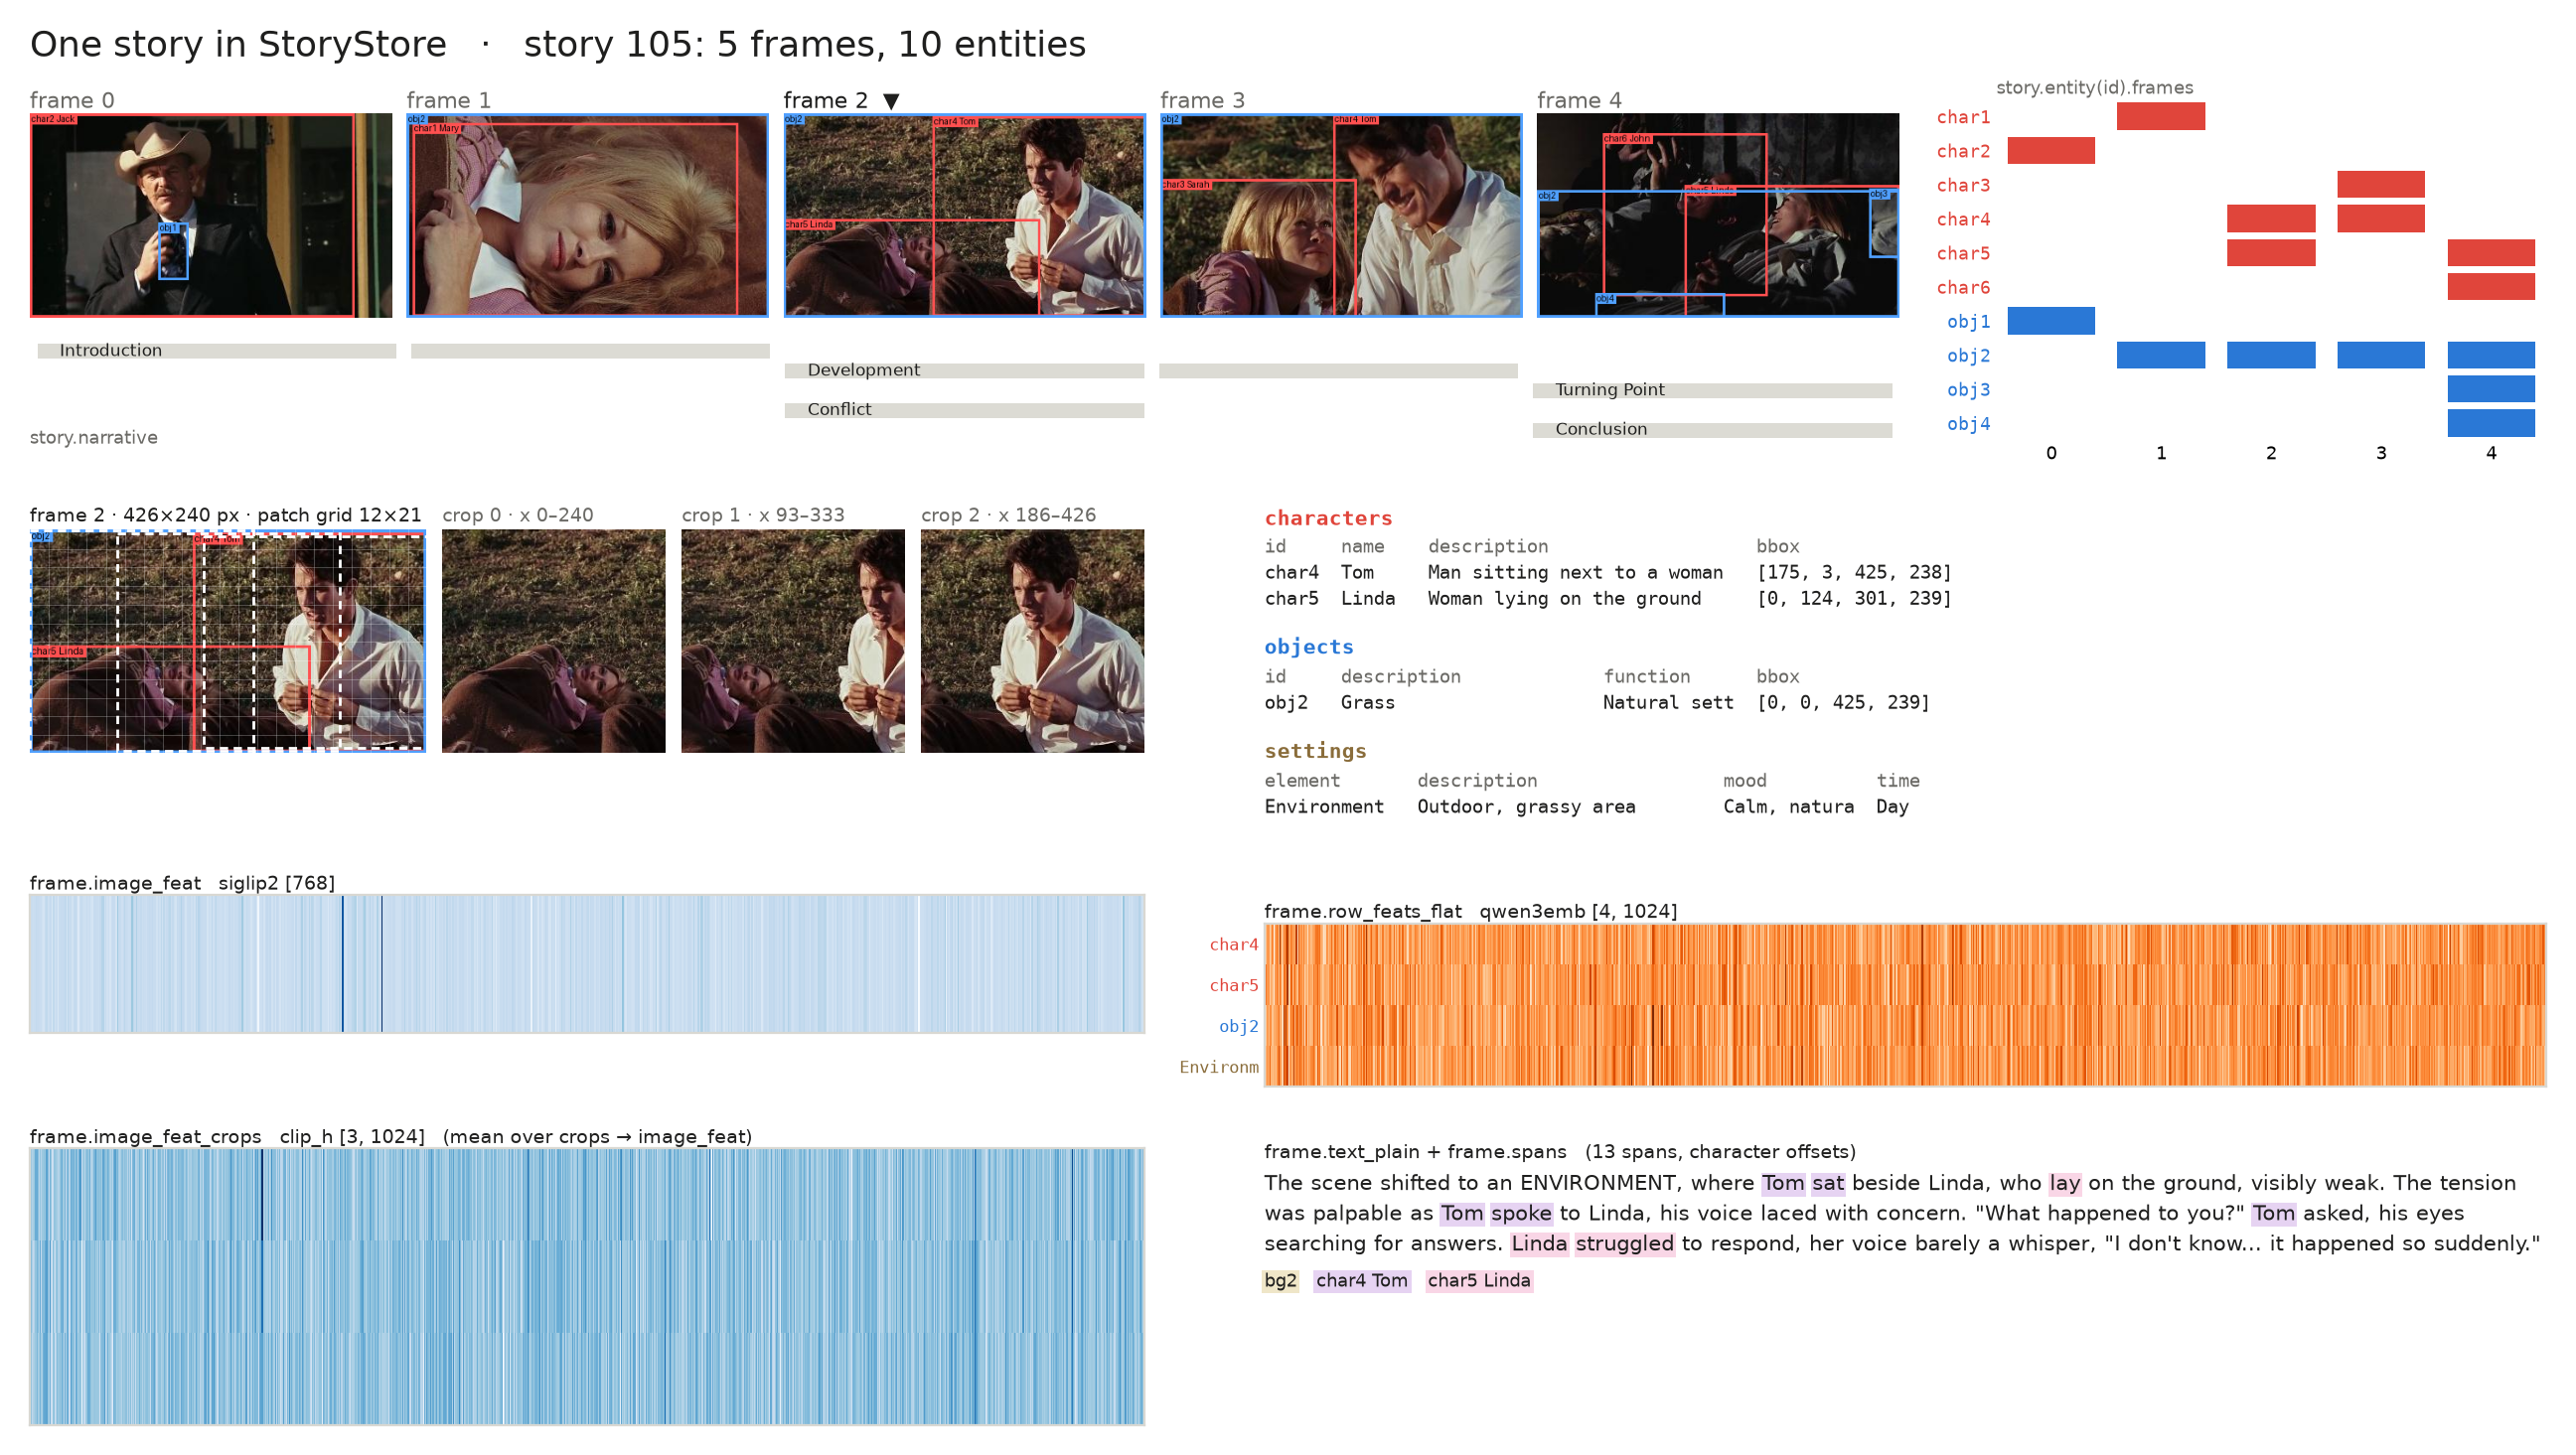

In [ ]:
s = store[0]
print(s)
print("frames:", s.n_frames, "| entities with a table row:", len(s.entity_ids), "| mentioned in the text:", len(s.mentioned_ids))
print()
for phase in s.narrative:
    print(f"{phase['phase']:<14} frames {phase['frames']}: {phase['description']}")
print()
print(s.text_plain[:600], "...")

## A frame

`s[i]` (or `s.frame(i)`) is a `FrameView`: the three tables of the chain of thought, the story segment with and without
grounding tags, the spans that link the two, and the features.

In [ ]:
f = s[1]
print(f)
display(pd.DataFrame(f.characters)[["id", "name", "description", "emotions", "actions", "narrative_function", "bbox"]])
display(pd.DataFrame(f.objects)[["id", "description", "function", "interaction", "bbox"]])
display(pd.DataFrame(f.settings)[["setting_element", "description", "mood", "time"]])

In [ ]:
print("tagged :", f.text[:300], "...")
print()
print("plain  :", f.text_plain[:300], "...")
print()
for sp in f.spans[:8]:
    print(f"  <{sp['tag']} {' '.join(sp['ids'])}>  {sp['surface']!r}  at [{sp['start']}:{sp['end']}] of text_plain")

## The picture, loaded lazily

`f.image` decodes the frame from the Hugging Face dataset the first time it is used (the dataset itself is downloaded
on the first call; it is about 1 GB). `f.image_with_boxes()` draws the table's bounding boxes: characters red, objects
blue, backgrounds green.

In [ ]:
display(f.image_with_boxes())

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(s), 1, figsize=(9, 1.9 * len(s)))
for ax, frame in zip(np.atleast_1d(axes), s):
    ax.imshow(frame.image_with_boxes(kinds=("characters",)))
    ax.set_title(f"frame {frame.index}: {frame.text_plain[:90]}...", fontsize=8, loc="left")
    ax.axis("off")
plt.tight_layout()

## Entities and their tracks

An entity ID is stable within a story. `s.entity(id)` collects its rows across frames, together with the row
embeddings of that track.

In [ ]:
eid = next(e for e in s.entity_ids if len(s.entity(e).frames) >= 3)
e = s.entity(eid)
print(e, "| mentioned in the story:", e.mentioned)
for row in e.rows:
    print(f"  frame {row['frame']}: {row['text']}")

# how much does the track's description drift? cosine between the first row and the others
t = e.feats.astype(np.float32)
t /= np.linalg.norm(t, axis=1, keepdims=True)
print("cosine to the first row:", np.round(t @ t[0], 3))

print("in tables but never mentioned:", [x for x in s.entity_ids if x not in s.mentioned_ids])

## The frozen features

Image features are one vector per frame (`image_feat`); row features come as one vector per table row, grouped by
table (`row_feats`). Everything is float32 when it reaches you; the files on disk are float16.

In [ ]:
print("image_feat        ", f.image_feat.shape, f.image_feat.dtype)
print("image_feat_crops  ", f.image_feat_crops.shape, "(1 crop for siglip2)")
print("patch grid        ", f.patch_grid, f"patches of 16 px for a {f.width} x {f.height} frame")
print("row_feats         ", {k: v.shape for k, v in f.row_feats.items()})
print("whole story       ", s.image_feats.shape)

### The CLIP-H view: three crops per frame

Open the same data with `img_encoder="clip_h"` to get the Stable-unCLIP-compatible space. Each frame has three
224 x 224 crops (left, centre, right); `image_feat` is their mean, `image_feat_crops` the three, and `crop_windows` says
where each crop sits in the frame.

In [ ]:
store_clip = StoryStore(ROOT, "train", img_encoder="clip_h", row_encoder=None, hf_dataset=store.hf_dataset)
fc = store_clip[0][1]
print("image_feat_crops", fc.image_feat_crops.shape, "| windows:", fc.crop_windows)

from PIL import ImageDraw
im = fc.image.copy()
for (x1, y1, x2, y2), colour in zip(fc.crop_windows, ["red", "yellow", "cyan"]):
    ImageDraw.Draw(im).rectangle([x1, y1, x2 - 1, y2 - 1], outline=colour, width=3)
display(im)

c = fc.image_feat_crops / np.linalg.norm(fc.image_feat_crops, axis=1, keepdims=True)
print("cosine between the crops:\n", np.round(c @ c.T, 3))

## The two dataset views for training

`StoryDataset` yields one story per item, `WindowedDataset(store, k)` one `(story, t)` per item with frames `t-k..t`
as context and frame `t`'s segment as target. Both are views over the store; collate functions pad frames and rows and
pass strings through as lists.

In [ ]:
from torch.utils.data import DataLoader

ds = StoryDataset(store)
batch = next(iter(DataLoader(ds, batch_size=4, shuffle=True, collate_fn=collate_stories)))
for k, v in batch.items():
    print(f"{k:<18}", tuple(v.shape) if torch.is_tensor(v) else f"list[{len(v)}]")

In [ ]:
wds = WindowedDataset(store, k=3)
print(len(wds), "windows")
batch = next(iter(DataLoader(wds, batch_size=8, shuffle=True, collate_fn=collate_windows)))
print("context image feats:", tuple(batch["image_feats"].shape), "| real frames per window:", batch["frame_mask"].sum(1).tolist())
print("target:", batch["target_text"][0][:200], "...")

## A first diagnostic: how similar are frames?

Before building anything, measure the space. Random pairs of frames vs consecutive frames of the same story: the gap
between the two is the signal a next-frame head can use. See the README for the other two diagnostics
(an indoor/outdoor linear probe and the copy-last-frame baseline).

In [ ]:
rng = np.random.default_rng(0)
img = store.img                                   # the memory-mapped [total_frames, D] array
idx = rng.choice(len(img), size=2000, replace=False)
x = np.asarray(img[np.sort(idx)], dtype=np.float32)
x /= np.linalg.norm(x, axis=1, keepdims=True)
cos = x @ x.T
random_pairs = cos[np.triu_indices(len(x), 1)].mean()

consecutive = []
for j in rng.choice(len(store), size=300, replace=False):
    feats = store[int(j)].image_feats
    feats /= np.linalg.norm(feats, axis=1, keepdims=True)
    consecutive.extend((feats[1:] * feats[:-1]).sum(1))
print(f"mean cosine, random frames:      {random_pairs:.3f}")
print(f"mean cosine, consecutive frames: {np.mean(consecutive):.3f}")